# Quantity graphs, GINE pooling and training

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Visible quantitative graph, pooling and training loop
Unit-safe quantities retain missingness rather than inferring mass-to-moles. Molecules are disjoint graphs. Component pooling averages atoms into molecules and then molecule embeddings by role. The loop clips finite gradients and selects checkpoints only on development folds.

## Retained baseline graph and GINE model
The retained model uses the original 11 atom features and role-aware pooling. These are its production graph/model definitions, not a random replacement. Constant names are aliased only so both feature versions can coexist in one notebook kernel. The trained checkpoint replay below verifies equivalence. Source hashes: graph `a435e84c1e6ba1d86d077133d89abb64d5b3bd79131d221391f03f189e568af4`, model `b08de1ef91832bbad7f268c25425e4650acacae7b2646107848c1146092090de`.

In [2]:
import math
import torch
from torch_geometric.data import Data
from reaction_gnn.data import canonical

NODE_DIM=11
EDGE_DIM=4

def reaction_graph(record):
    nodes=[];edges=[];bonds=[]
    for component in record["components"]:
        role=component["role"]
        if role not in range(4): raise ValueError("Input role must be 0..3")
        _,mol=canonical(component["smiles"]);offset=len(nodes)
        for atom in mol.GetAtoms():
            features=[atom.GetAtomicNum()/100,atom.GetDegree()/4,atom.GetFormalCharge()/4,atom.GetTotalNumHs()/4,float(atom.GetIsAromatic()),float(atom.IsInRing()),atom.GetMass()/200]+[float(role==i) for i in range(4)]
            nodes.append(features)
        for bond in mol.GetBonds():
            a,b=bond.GetBeginAtomIdx()+offset,bond.GetEndAtomIdx()+offset
            attributes=[bond.GetBondTypeAsDouble()/3,float(bond.GetIsConjugated()),float(bond.IsInRing()),float(bond.GetIsAromatic())]
            edges.extend([(a,b),(b,a)]);bonds.extend([attributes,attributes])
    if not nodes: raise ValueError("Empty reaction graph")
    temperature=record.get("temperature_c")
    if temperature is not None and not math.isfinite(float(temperature)):
        raise ValueError("temperature_c must be finite or null")
    graph=Data(x=torch.tensor(nodes,dtype=torch.float32),edge_index=torch.tensor(edges,dtype=torch.long).t().contiguous() if edges else torch.empty((2,0),dtype=torch.long),edge_attr=torch.tensor(bonds,dtype=torch.float32).reshape(-1,EDGE_DIM),conditions=torch.tensor([[temperature/100 if temperature is not None else 0.,float(temperature is None)]],dtype=torch.float32))
    if "yield_percent" in record: graph.y=torch.tensor([record["yield_percent"]/100],dtype=torch.float32)
    return graph

legacy_reaction_graph = reaction_graph


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
import torch
from torch import nn
from torch_geometric.nn import GINEConv,global_mean_pool
from reaction_gnn.graph import NODE_DIM as LEGACY_NODE_DIM, EDGE_DIM as LEGACY_EDGE_DIM

class YieldGNN(nn.Module):
    def __init__(self,hidden=48,layers=3,pooling="global",dropout=0.):
        super().__init__();self.hidden=hidden;self.layers=layers;self.pooling=pooling;self.dropout=dropout
        self.encoder=nn.Linear(LEGACY_NODE_DIM,hidden)
        self.convs=nn.ModuleList([GINEConv(nn.Sequential(nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,hidden)),edge_dim=LEGACY_EDGE_DIM) for _ in range(layers)])
        self.head=nn.Sequential(nn.Linear(hidden*(4 if pooling=="role" else 1)+2,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self,batch):
        x=torch.relu(self.encoder(batch.x))
        for conv in self.convs: x=torch.relu(conv(x,batch.edge_index,batch.edge_attr)+x)
        if self.pooling=="role":
            # Distinguish substrates/reagents/solvents/catalysts instead of diluting them.
            roles=batch.x[:,7:11].argmax(1);pooled=[]
            for role in range(4):
                selected=roles==role
                pooled.append(global_mean_pool(x[selected],batch.batch[selected],size=batch.num_graphs))
            pooled=torch.cat(pooled,dim=1)
        else: pooled=global_mean_pool(x,batch.batch)
        return torch.sigmoid(self.head(torch.cat([pooled,batch.conditions],dim=1))).flatten()


### Visible production core: `src/reaction_gnn/quantity_graph.py`

These readable definitions are copied from the executed production module (SHA256 `623114639c944efe3b5aa47ef2bee6a047b5d39bfbed665e3bda9498e6a53eed`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [4]:
"""Quantity-aware graph version2 with explicit component boundaries."""
import math
import numpy as np
import torch
from reaction_gnn.graph import reaction_graph as legacy_graph

NODE_DIM=13
CONDITION_DIM=16


def quantitative_conditions(record):
    components=record['components'];moles=[];volumes=[]
    for c in components:
        if isinstance(c['role'],bool) or not isinstance(c['role'],int) or c['role'] not in range(4):raise ValueError('Input role must be 0..3')
        if not isinstance(c.get('is_limiting',False),bool):raise ValueError('is_limiting must be boolean')
        values=[]
        for key in ['moles','volume_l']:
            value=c.get(key)
            if value is not None and (isinstance(value,bool) or not isinstance(value,(int,float)) or not math.isfinite(value) or value<0):raise ValueError('Input amount must be finite nonnegative or null')
            values.append(value)
        moles.append(values[0]);volumes.append(values[1])
    reference=[m for c,m in zip(components,moles) if c['role']==0 and c.get('is_limiting',False) and m is not None and m>0]
    if not reference:reference=[m for c,m in zip(components,moles) if c['role']==0 and m is not None and m>0]
    reference=min(reference) if reference else None
    equivalents=[m/reference if m is not None and reference is not None else None for m in moles]
    if any(v is not None and not math.isfinite(v) for v in equivalents):raise ValueError('Nonfinite stoichiometric ratio')
    def scaled(value):return math.log1p(min(value,1000.))/math.log(1001.)
    temperature=record.get('temperature_c')
    if temperature is not None and (not isinstance(temperature,(int,float)) or isinstance(temperature,bool) or not math.isfinite(temperature)):raise ValueError('Finite temperature required')
    condition=[float(temperature)/100 if temperature is not None else 0.,float(temperature is None)]
    for role in range(4):condition.append(scaled(sum(v for c,v in zip(components,equivalents) if c['role']==role and v is not None)))
    for role in range(4):
        selected=[v for c,v in zip(components,equivalents) if c['role']==role]
        condition.append(sum(v is None for v in selected)/len(selected) if selected else 1.)
    for role in range(4):condition.append(math.log1p(sum(c['role']==role for c in components))/math.log(11.))
    volume=sum(v for v in volumes if v is not None)
    concentration=reference/volume if reference is not None and volume>0 else None
    if concentration is not None and not math.isfinite(concentration):raise ValueError('Nonfinite input concentration')
    condition.extend([scaled(concentration) if concentration is not None else 0.,float(concentration is None)])
    if len(condition)!=CONDITION_DIM or not np.isfinite(condition).all():raise ValueError('Nonfinite quantity conditions')
    node_quantities=[[scaled(v) if v is not None else 0.,float(v is None)] for v in equivalents]
    return np.asarray(condition,dtype=np.float32),node_quantities


def reaction_graph(record):
    conditions,quantities=quantitative_conditions(record);graph=legacy_graph(record)
    from reaction_gnn.data import canonical
    local=[];amounts=[]
    for index,(component,quantity) in enumerate(zip(record['components'],quantities)):
        _,mol=canonical(component['smiles']);count=mol.GetNumAtoms()
        local.extend([index]*count);amounts.extend([quantity]*count)
    graph.x=torch.cat([graph.x,torch.tensor(amounts,dtype=torch.float32)],dim=1)
    graph.conditions=torch.tensor(conditions[None,:],dtype=torch.float32)
    graph.component_local=torch.tensor(local,dtype=torch.long)
    graph.component_roles=torch.tensor([c['role'] for c in record['components']],dtype=torch.long)
    return graph


### Visible production core: `src/reaction_gnn/quantity_model.py`

These readable definitions are copied from the executed production module (SHA256 `274de3a04b352936d85e4ddd621fc40ca6546c44282f9d802d6c65bb6c76aec8`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [5]:
"""Bond-aware quantitative GNN with atom or component-balanced role pooling."""
import torch
from torch import nn
from torch_geometric.nn import GINEConv,global_mean_pool
from reaction_gnn.quantity_graph import NODE_DIM,CONDITION_DIM


class QuantityGNN(nn.Module):
    feature_version=2
    def __init__(self,hidden=48,layers=3,pooling='component_role',dropout=0.):
        super().__init__()
        if pooling not in ['atom_role','component_role']:raise ValueError('Unknown quantity pooling')
        self.hidden=hidden;self.layers=layers;self.pooling=pooling;self.dropout=dropout
        self.encoder=nn.Linear(NODE_DIM,hidden)
        self.convs=nn.ModuleList([GINEConv(nn.Sequential(nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,hidden)),edge_dim=4) for _ in range(layers)])
        self.head=nn.Sequential(nn.Linear(hidden*4+CONDITION_DIM,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,1))

    def forward(self,batch):
        x=torch.relu(self.encoder(batch.x))
        for conv in self.convs:x=torch.relu(conv(x,batch.edge_index,batch.edge_attr)+x)
        if self.pooling=='component_role':
            index=batch.component_local+batch.component_roles_ptr[batch.batch]
            x=global_mean_pool(x,index,size=len(batch.component_roles));roles=batch.component_roles;assignment=batch.component_roles_batch
        else:roles=batch.x[:,7:11].argmax(1);assignment=batch.batch
        pooled=[]
        for role in range(4):
            selected=roles==role
            pooled.append(global_mean_pool(x[selected],assignment[selected],size=batch.num_graphs))
        pooled=torch.cat(pooled,dim=1)
        return torch.sigmoid(self.head(torch.cat([pooled,batch.conditions],dim=1))).flatten()


In [6]:
from copy import deepcopy
from torch_geometric.loader import DataLoader
from reaction_gnn.train import metrics

### Visible production core: `src/reaction_gnn/quantity_study.py`

These readable definitions are copied from the executed production module (SHA256 `45d96b68b3016bbe7a08379b989184c0a7c35c341141b5b32ce105f2a0202eed`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used.

In [7]:
def loader(graphs,version,batch_size=32,shuffle=False,seed=42):
    return DataLoader(graphs,batch_size=batch_size,shuffle=shuffle,generator=torch.Generator().manual_seed(seed),follow_batch=['component_roles'] if version==2 else [])


def predictions(model,graphs,version):
    model.eval()
    with torch.no_grad():values=torch.cat([model(batch) for batch in loader(graphs,version)]).numpy()*100
    if not np.isfinite(values).all() or (values<0).any() or (values>100).any():raise ValueError('Invalid model forecasts')
    return values


def model_for(config,fixed):
    cls=YieldGNN if config['feature_version']==1 else QuantityGNN
    return cls(fixed['hidden'],fixed['layers'],config['pooling'],fixed['dropout'])


def fit_graph(graphs,validation,config,fixed,seed,epochs=None):
    torch.manual_seed(seed);model=model_for(config,fixed)
    optimizer=torch.optim.AdamW(model.parameters(),lr=fixed['lr'],weight_decay=fixed['weight_decay'])
    batches=loader(graphs,config['feature_version'],fixed['batch_size'],True,seed)
    history=[];best=float('inf');state=None;best_epoch=0
    maximum=epochs if epochs is not None else fixed['max_epochs']
    for epoch in range(maximum):
        model.train();total=0.;maximum_gradient=0.
        for batch in batches:
            output=model(batch)
            loss=torch.nn.functional.mse_loss(output,batch.y) if config['loss']=='mse' else torch.nn.functional.smooth_l1_loss(output,batch.y,beta=config['beta'])
            if not bool(torch.isfinite(loss)):raise ValueError('Nonfinite training loss')
            optimizer.zero_grad();loss.backward()
            norm=torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
            maximum_gradient=max(maximum_gradient,float(norm));optimizer.step();total+=float(loss.detach())*batch.num_graphs
        item={'epoch':epoch+1,'train_loss_fraction':total/len(graphs),'maximum_gradient_norm_before_clip':maximum_gradient}
        if validation is not None:
            graph_val,target=validation;score=metrics(target,predictions(model,graph_val,config['feature_version']))['mae_percentage_points'];item['validation_mae']=score
            if score<best:best=score;state=deepcopy(model.state_dict());best_epoch=epoch+1
        history.append(item)
        if validation is not None and epoch+1>=fixed['minimum_epochs'] and epoch+1-best_epoch>=fixed['early_stopping_patience']:break
    if validation is not None:
        if state is None:raise ValueError('No finite validation checkpoint')
        model.load_state_dict(state)
    return model,best_epoch if validation is not None else maximum,history


def save_model(model,config,fixed,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({'state_dict':model.state_dict(),'hidden':fixed['hidden'],'layers':fixed['layers'],'pooling':config['pooling'],'dropout':fixed['dropout'],'feature_version':config['feature_version']},path)


def select_gnn(trials):
    baseline=next(t for t in trials if t['config']['feature_version']==1)
    eligible=[baseline]
    for t in trials:
        if t is baseline:continue
        wins=sum(x<y for x,y in zip(t['fold_validation_mae'],baseline['fold_validation_mae']))
        if t['mean_validation_mae']<=baseline['mean_validation_mae']-.5 and wins>=2:eligible.append(t)
    return min(eligible,key=lambda t:t['mean_validation_mae'])


## Actual validation ablations
The gate was fixed before scoring: at least 0.5-point improvement and two fold wins. No candidate met it across quantity, fingerprint and loss-only rounds. This table preserves all attempted procedures; it does not force a new model.

,mean_mae,fold_0,fold_1,fold_2
candidate,,,,
legacy_role48,23.566776,23.589201,24.182208,22.928919
quantity_atom_role48,23.872097,23.961622,24.728771,22.925897
quantity_component_role48,23.585006,23.819896,24.073581,22.861540
quantity_component_huber48,23.342044,23.418933,23.514513,23.092687
legacy_huber01,23.989624,23.619192,24.563953,23.785728
legacy_huber001,24.066958,23.773913,24.464860,23.962101
component_huber001,23.718275,24.104654,23.695856,23.354314


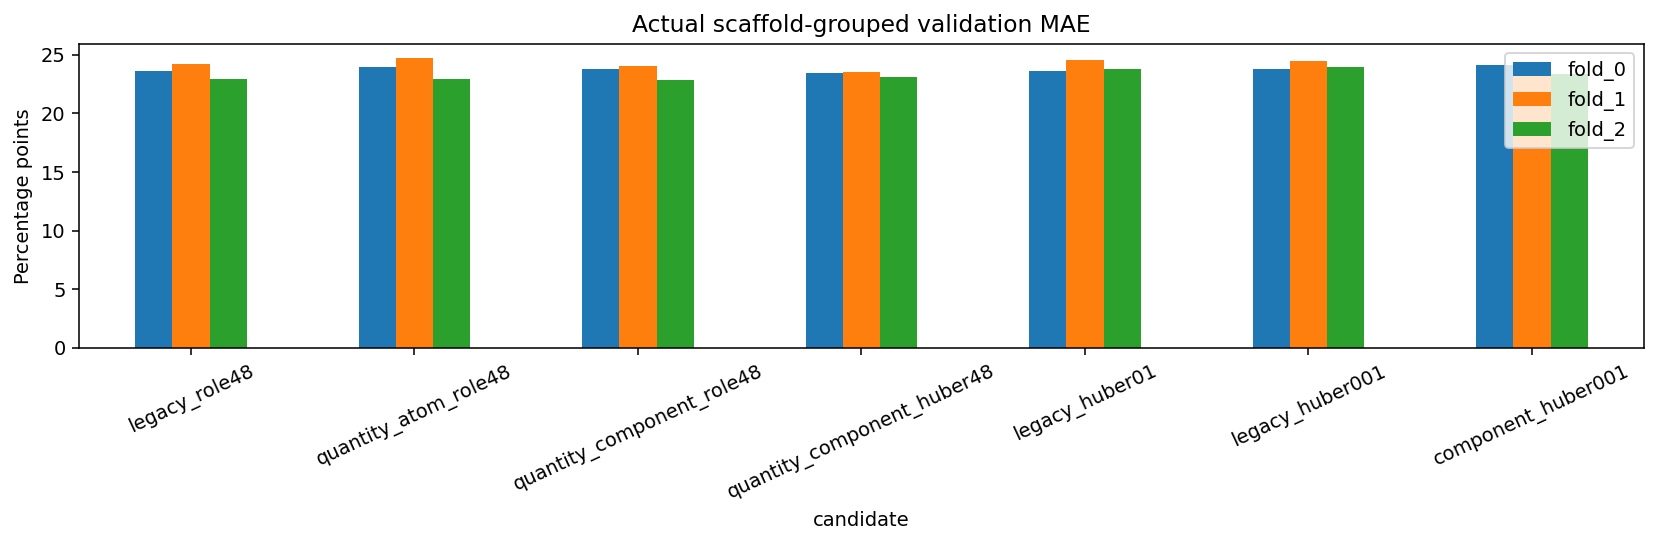

In [8]:
selection=read_json('docs/quantity-v2/selection.json')
trials=selection['gnn_trials']+read_json('docs/loss-v4/loss-validation.json')['trials']
rows=[{'candidate':row['config']['name'],'mean_mae':row['mean_validation_mae'],**{f'fold_{i}':v for i,v in enumerate(row['fold_validation_mae'])}} for row in trials]
comparison=pd.DataFrame(rows).set_index('candidate')
display(comparison)
fig,ax=plt.subplots(figsize=(12,4))
comparison[['fold_0','fold_1','fold_2']].plot.bar(ax=ax)
ax.set(title='Actual scaffold-grouped validation MAE',ylabel='Percentage points')
ax.tick_params(axis='x',rotation=25)
show_figure(fig,'reaction_gnn_fold_comparison')

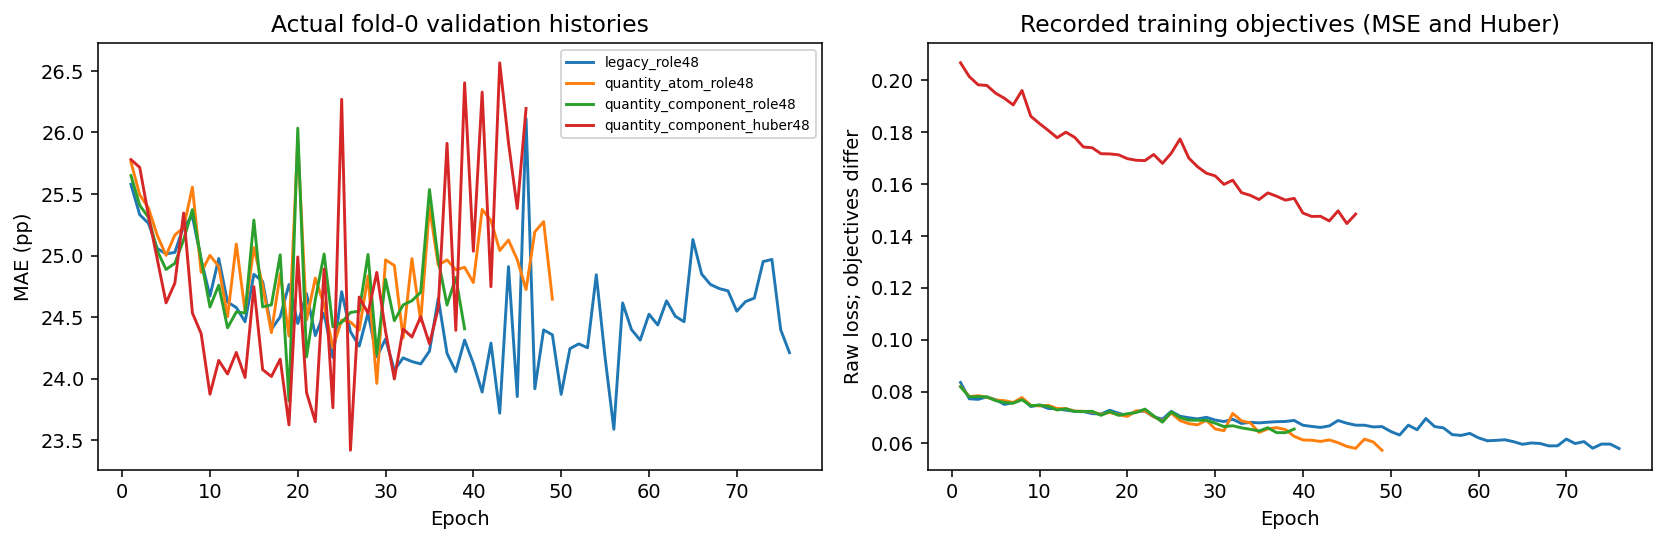

MSE and Huber losses use different objectives; vertical loss values are not directly comparable.


In [9]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for row in selection['gnn_trials']:
    history=pd.DataFrame(row['history'][0])
    axes[0].plot(history.epoch,history.validation_mae,label=row['config']['name'])
    axes[1].plot(history.epoch,history.train_loss_fraction,label=row['config']['name'])
axes[0].set(title='Actual fold-0 validation histories',xlabel='Epoch',ylabel='MAE (pp)')
axes[1].set(title='Recorded training objectives (MSE and Huber)',xlabel='Epoch',ylabel='Raw loss; objectives differ')
axes[0].legend(fontsize=7)
show_figure(fig,'reaction_actual_training_curves')
print('MSE and Huber losses use different objectives; vertical loss values are not directly comparable.')

## Optional full training
Visible loop definitions above are executable. Full production study is opt-in, uses real prepared data and creates fresh artifacts. It never scores the historically observed ELN holdout.

In [10]:
RUN_TRAIN=False
if RUN_TRAIN:
    import subprocess
    from datetime import datetime,timezone
    output='docs/notebook-quantity-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    subprocess.run([sys.executable,'train.py','--output',output],check=True)
print('Analysis execution did not train or rescore a test:',not RUN_TRAIN)

Analysis execution did not train or rescore a test: True


## Recorded training identity and retained checkpoint
The curves above are recorded fold histories. This cell shows the exact configuration/environment and frozen release identity; no training is performed here.

In [11]:
print('Fixed training config:',read_json('docs/quantity-plan.json')['fixed_training'])
print('Recorded environment:',selection['environment'])
print('Quantity scientific runtime seconds:',selection['runtime_seconds'])
release=read_json('docs/loss-v4/ELN-results.json')
print('Retained final configuration:',release['selected_gnn'])
print('Final refit epochs:',release['final_refit_epochs'])
print('Actual checkpoint SHA256:',release['gnn_checkpoint_sha256'])
print('Production save/reload delta:',release['actual_checkpoint_example_delta'])

Fixed training config: {'hidden': 48, 'layers': 3, 'lr': 0.003, 'weight_decay': 0.0001, 'dropout': 0.0, 'batch_size': 24, 'max_epochs': 120, 'minimum_epochs': 20, 'early_stopping_patience': 20, 'seeds': '42+fold for fitting;42 for final refit', 'threads': 2, 'device': 'cpu'}
Recorded environment: {'python': '3.14.2', 'torch': '2.14.0+cpu', 'threads': 2, 'device': 'cpu', 'packages': {'torch-geometric': '2.8.1', 'rdkit': '2026.3.6', 'numpy': '2.4.2', 'scikit-learn': '1.8.0', 'ord-schema': '0.9.3', 'pyarrow': '25.0.1'}}
Quantity scientific runtime seconds: 925.5551836999948
Retained final configuration: {'name': 'legacy_role48', 'feature_version': 1, 'pooling': 'role', 'loss': 'mse'}
Final refit epochs: 47
Actual checkpoint SHA256: a23bf986ffaa53d6003dd6648f98141b697438c790c9bb8ebc60adab50ec2e97
Production save/reload delta: 0.0


## Run the visible baseline class with actual learned weights
This loads the frozen trained state into the inline class above and compares its public-example forecast with production inference. No training or test scoring occurs; the equality checks architecture/feature consistency.

In [12]:
from torch_geometric.data import Batch
from reaction_gnn.train import load_model,predict_record
production=load_model('models/loss-v4/selected.pt')
inline=YieldGNN(production.hidden,production.layers,production.pooling,production.dropout)
inline.load_state_dict(production.state_dict())
inline.eval()
example={'components':[{'smiles':'Brc1ccccc1','role':0},{'smiles':'Nc1ccccc1','role':0},{'smiles':'CCO','role':2}],'temperature_c':80.}
with torch.no_grad():
    inline_value=float(inline(Batch.from_data_list([legacy_reaction_graph(example)]))[0])*100
production_value=predict_record(production,example)
assert abs(inline_value-production_value)<1e-7
print('Inline trained GNN example yield (%):',inline_value)
print('Difference from production inference:',abs(inline_value-production_value))

Inline trained GNN example yield (%): 28.50843071937561
Difference from production inference: 0.0
